<h1 style = "color: #000080;"><strong><em><center>Tabletop Game Simulation Study - Mean & Standard Deviation</strong></em></center></h1>

<h2 style = "color: #000080;"><strong><center>Statistical Investigation Question:</strong></center></h2>

<h3 style = "color: #000080;"><center>If two players play Connect 4 by choosing a random valid column on every turn, what are the mean and standard deviation of the total number of moves required to complete a game?</center></h3>

<h2 style = "color: #000080;"><strong><center>Type of Simulation:</strong></center></h2>

<h3 style = "color: #000080;">1. I am simulating a random valid column, which is my simulation's random variable. It can take in only discrete values that are quantitative, since the columns in this tabletop game are from 1 to 7. In other words, there are 7 columns to choose from in Connect 4.</h3>

<h3 style = "color: #000080;">2. One trial will be the act of either player placing a token into any column (columns 1-7). Its possible outcome is where the token ends up on the vertical board.</h3>

<h2 style = "color: #000080;"><strong><center>Simulation Code:</strong></center></h2>

In [43]:
# Import necessary libraries.
# (Imports built-in tools for choosing random items & processing statistics).
import random
import pandas as pd

In [44]:
# List to store the total moves of all 10,000 simulated games.
# (An empty list to store the final move count of every simulated game (10,000 numbers total).
results = []

In [45]:
# Loop 10,000 times to simulate 10,000 full games.

# Loops 10,000 times so we can play 10,000 full Connect 4 games back-to-back.
for game in range(10000):
    # Creates a 6-row by 7-column ngrid filled with zeros (0 = empty spot).
    board = [[0] * 7 for _ in range(6)]  # 6-row by 7-column grid initialized to 0.
    # Tracks how many pieces are stacked in each column (0 to 6).
    heights = [0] * 7                    # Tracks number of pieces in each column.
    # Starts the current game's turn counter at zero.
    moves = 0                            # Move counter for current game.
    # Sets Player 1 to go first.
    player = 1                           # Active player (1 or 2).
    # A flag to keep the game running until someone wins or fills the board.
    game_over = False

    # Keeps taking turns until all 42 board slots are full or a player wins.
    while moves < 42 and not game_over:
        # Find columns that are not full.
        # Scans columns 0 through 6 & keeps only the ones that aren't full yet (height < 6).
        valid_cols = [col for col in range(7) if heights[col] < 6]
        # Ends the loop if all columns are completely full (a tie game).
        if not valid_cols:
            break                        # Grid is full (tie game).

        # Pick a column at random & drop a piece.
        # (Randomly selects one open column.)
        col = random.choice(valid_cols)
        # Finds the lowest available row in that column.
        row = heights[col]
        # Places the current player's token (1 or 2) in that cell.
        board[row][col] = player
        # Increases that column's height tracker by 1.
        heights[col] += 1
        # Increases the game's move counter by 1.
        moves += 1

        # Check if this move created a 4-in-a-row.
        # The 4 mathematical directions to check:
        # (0,1) = Horizontal.
        # (1,0) = Vertical.
        # (1,1) = Diagonal UP-RIGHT.
        # (1,-1) = Diagonal DOWN-RIGHT.
        directions = [(0, 1), (1, 0), (1, 1), (1, -1)]
        # Loops through each of the 4 directions.
        for dr, dc in directions:
            # Starts the connected piece count at 1 (for the token just placed).
            count = 1
            # Checks both forward (1) & backward (-1) along that direction line.
            for step in (1, -1):
                # Calculates the coordinates of the neighboring grid cell.
                nr, nc = row + dr * step, col + dc * step
                # As long as the neighbor is inside board boundaries & belongs to the active player:
                while 0 <= nr < 6 and 0 <= nc < 7 and board[nr][nc] == player:
                    # Add 1 to matching connected tokens.
                    count += 1
                    # Step one cell further along that same line.
                    nr, nc = nr + dr * step, nc + dc * step

            # If 4 or more matching pieces are connected, flag the game as over & stop checking directions.
            if count >= 4:
                game_over = True
                break

        # Switch players for the next turn.
        # (Switches active player after every turn (3 - 1 = 2, & 3 - 2 = 1).
        player = 3 - player

    # Record total moves for this game.
    # (Once a game ends, appends its total move count to the results list.
    results.append(moves)

# Convert results list to Pandas Series & compute statistics.
# (Converts all 10,000 game move counts into a Pandas Series object so you can calculate standard deviation (s.std()) & mean (s.mean()).
s = pd.Series(results)

In [46]:
# Print the average number of total moves.
print("Mean total moves:", round(s.mean(), 2))
# Print the value of the standard deviation in this scenario.
print("Standard Deviation:", round(s.std(), 2))

Mean total moves: 21.4
Standard Deviation: 7.35


<h2 style = "color: #000080;"><strong><center>Simulation Graph & Code:</strong></center></h2>

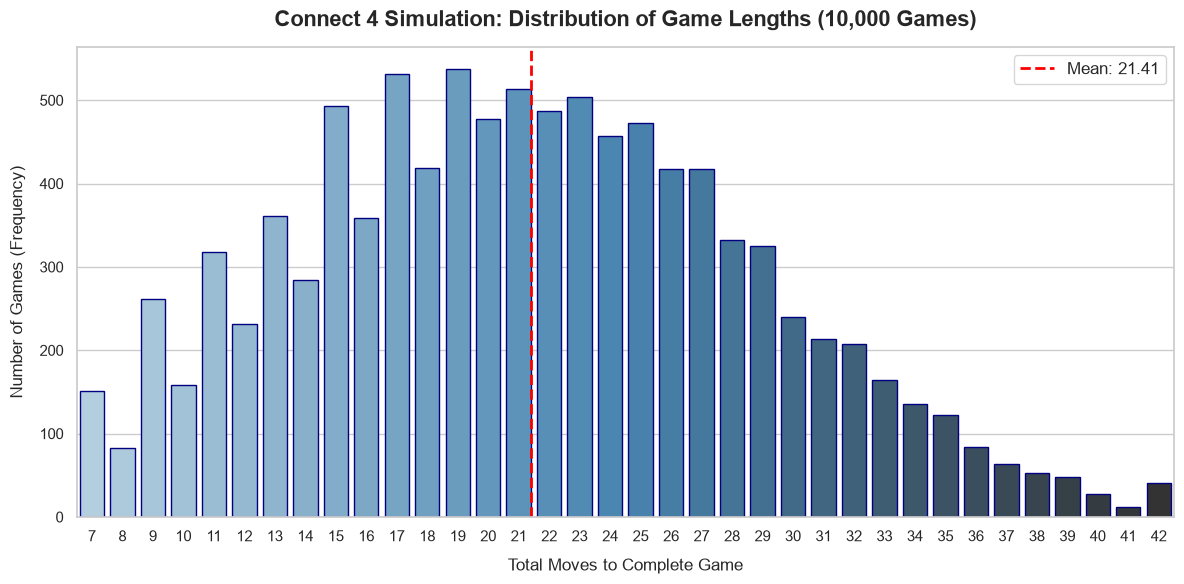

In [47]:
# Imports the two visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Applies a clean theme with horizontal white grid lines behind the bars.
sns.set_theme(style="whitegrid")
# Creates a blank figure canvas with a width of 12 inches & height of 6 inches.
plt.figure(figsize=(12, 6))

# "s.value_counts()" counts how many games ended at each turn length (e.g., 200 games ended in 15 moves).
# ".sortindex()" sorts those move counts in order from lowest (move 7) to highest (move 42).
move_counts = s.value_counts().sort_index()

# Seaborn bar plot with hue fixed to prevent warnings.
ax = sns.barplot(
    # Uses the game turn numbers (7, 8, 9... 42) for the x-axis positions.
    x=move_counts.index,
    # Uses the frequency of games for the bar heights.
    y=move_counts.values, 
    # Links bar colors to x-axis positions to allow color palettes without triggering warnings or generating an unncessary color key.
    hue=move_counts.index,
    # Applies a dark-to-light blue gradient across the bars.
    palette="Blues_d",
    # Adds a crisp dark navy border around each individual bar.
    edgecolor="navy",
    # Links bar colors to x-axis positions to allow color palettes without triggering warnings or generating an unnecessary color key.
    legend=False
)

# Adds the top headline with bold formatting & padding above the graph.
plt.title("Connect 4 Simulation: Distribution of Game Lengths (10,000 Games)", fontsize=16, fontweight="bold", pad=15)
# Adds descriptive titles to the bottom & left axes with extra padding so they don't crowd the numbers.
plt.xlabel("Total Moves to Complete Game", fontsize=12, labelpad=10)
plt.ylabel("Number of Games (Frequency)", fontsize=12, labelpad=10)

# Calculate exact position for mean line on categorical axis.
# (Calculates the exact numerical average from the 10,000 games (e.g., 21.41)).
mean_val = s.mean()
# "list(move_counts.index).index(int(mean_val))" finds which bar position represents the integer part of the mean (move 21).
# ("mean_val % 1") extracts the decimal remainder (e.g., 0.28). Adding this shifts the line slightly past bar 21 toward bar 22 so it sits at the exact mathematical position.
x_position = list(move_counts.index).index(int(mean_val)) + (mean_val % 1)

# Draws the vertical dashed (--) red line across the graph & registers its label for the legend.
plt.axvline(x=x_position, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_val:.2f}")

# Displays the legend box showing the mean value in the top-right corner.
plt.legend(fontsize=12, loc="upper right")
# Adjusts margins automatically so no titles or labels get cut off.
plt.tight_layout()
# Renders the complete visual in notebook output.
plt.show()

<h2 style = "color: #000080;"><strong><center>Statistical Investigation Answer:</strong></center></h2>

<h3 style = "color: #000080;"><center>My simulation of the tabletop game Connect 4 produced an accurate mean and standard deviation after simulating 10,000 games. According to the collected data, the mean total number of moves was approximately 21.41 moves, and the standard deviation was about 7.43. In this scenario, the mean signifies how many moves it took on average to complete a single match. The standard deviation measures how much the total moves per game varied around that average.</center></h3>

<h2 style = "color: #000080;"><strong><center>Tabletop Game (Connect 4) Desmos Graph:</strong></center></h2>

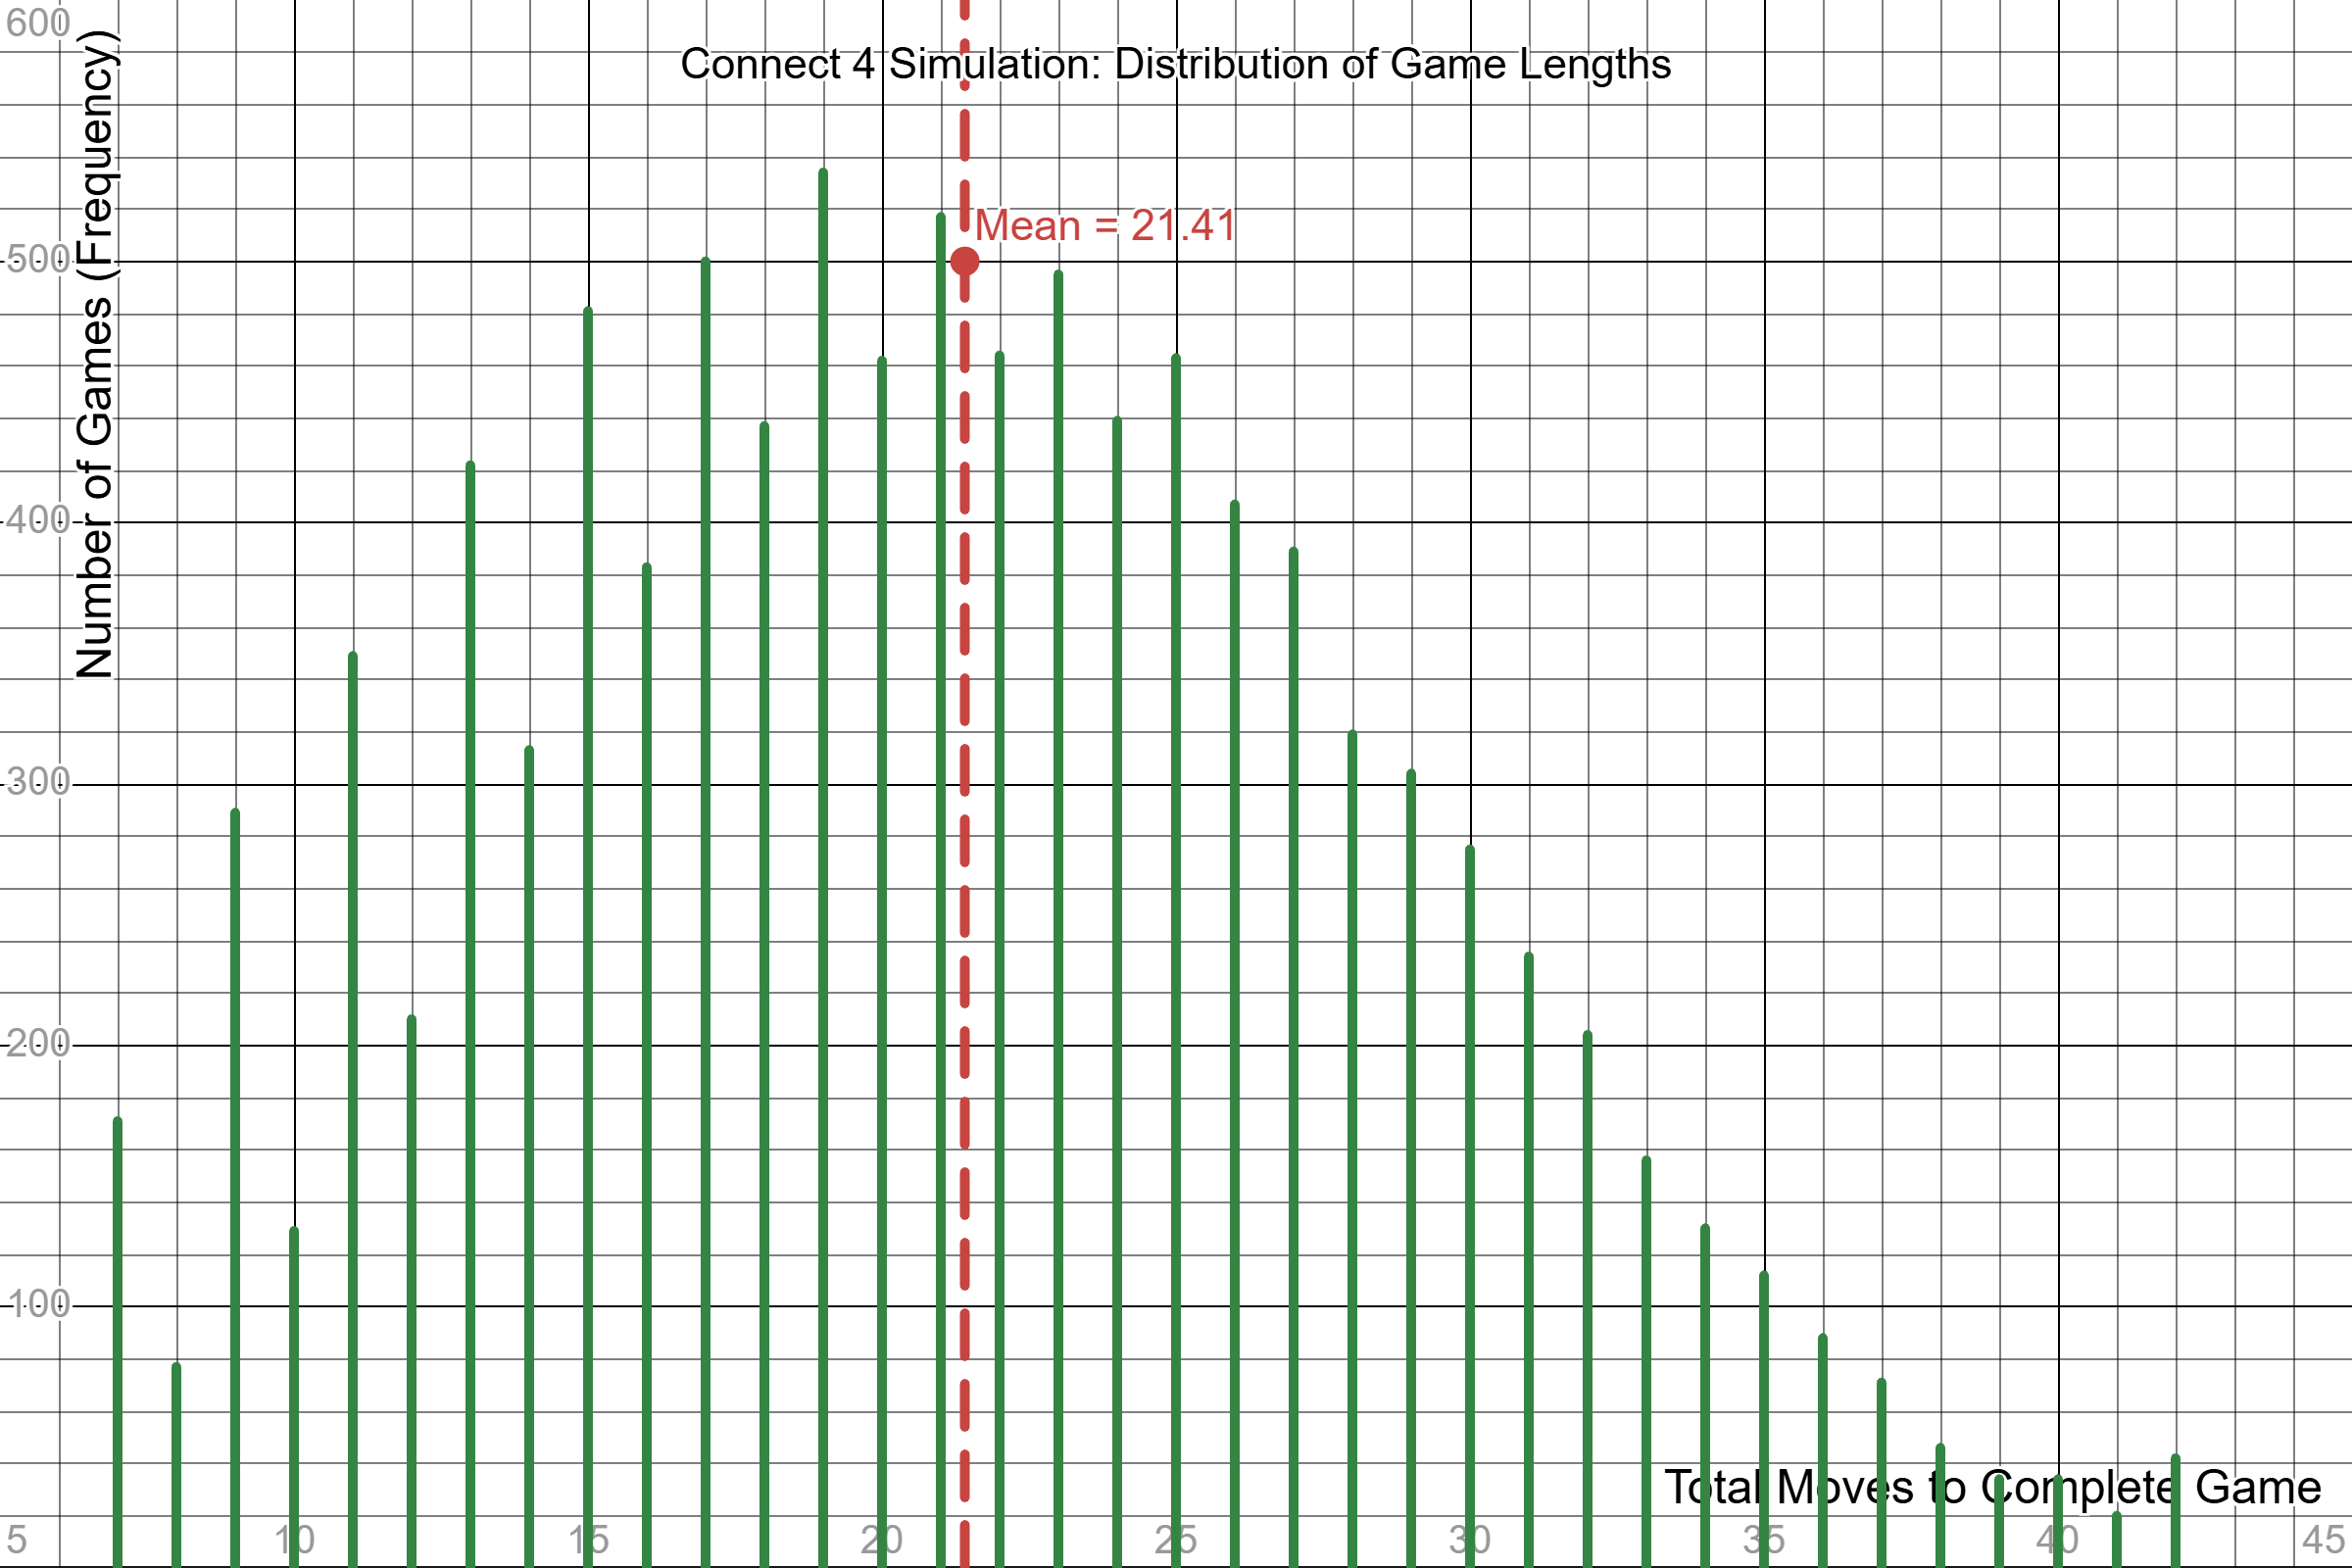

In [50]:
from IPython.display import Image, display
display(Image(filename="Connect 4 Desmos Graph.png", width=1000))

<h2 style = "color: #000080;"><strong><center>Desmos Graph Interpretation & Connect 4 Tabletop Game Conclusion:</strong></center></h2>

<h3 style = "color: #000080;"><center>Desmos Graph Interpretation: According to the graph above, the average number of moves to complete a single match in Connect 4 is about 21.41 moves across 10,000 simulated matches. The bar chart distribution is nearly symmetrical and bell-shaped. While the standard deviation isn't explicitly drawn as an area on the chart, we can see the full spread of data, including the rare occurrences in the far tails (such as matches ending in under 10 moves or over 38 moves).</center></h3>

<h3 style = "color: #000080;"><center>Connect 4 Tabletop Game Conclusion: In a large sample of Connect 4 games, two players choosing random valid moves can expect a match to last roughly 21.41 moves on average. However, individual matches naturally vary from this expected length due to random play. This variability is quantified by the standard deviation (approximately 7.43), which measures how far game lengths typically spread around the mean. For example, while the average is around 21 to 22 moves, a specific match might end in 15 moves or extend up to 30 moves.</center></h3>

In [49]:
from IPython.display import HTML, display

sky_blue_css = """
<script>
    var style = document.createElement('style');
    style.innerHTML = `
        body, .jp-Notebook, div#notebook-container {
            background-color: #00BFFF !important;
        }
        .jp-Cell, div.cell {
            background-color: #70D6FF !important;
            border-radius: 8px;
            margin-bottom: 10px;
        }
    `;
    document.head.appendChild(style);
</script>
"""
display(HTML(sky_blue_css))